# 3D antenna pattern interpolation from 2D plane cuts

This notebook demonstrates the 3D interpolation algorithm of an antenna pattern, starting from the vertical cuts. The alogrithm is described in [this paper](https://ieeexplore.ieee.org/document/6408150).

Cite as:

T. Petrita and A. Ignea, *"A new method for interpolation of 3D antenna pattern from 2D plane patterns"*, 2012 10th International Symposium on Electronics and Telecommunications, Timisoara, Romania, 2012, pp. 393-396, doi: 10.1109/ISETC.2012.6408150.*

This is the GNU Octave / Matlab version.

In [1]:
# Preamble: some settings
set(0, "defaulttextfontsize", 24)  % title
set(0, "defaultaxesfontsize", 16)  % axes labels
set(0, "defaultlinelinewidth", 2)
clear all

In [2]:
# Step 1: Get the data
work_folder = 'G:\My Drive\A205\ant_pattern'; % put your path here
work_file = '742215_2140_CO_P45_00T.txt';
pattern_data = [work_folder,'\',work_file];
pattern = dlmread(pattern_data); 
size(pattern)

ans =

   65341       4



In [3]:
# Step 2: slice and reshape
theta_deg = pattern(:,1);
phi_deg = pattern(:,2);
amp_dB = pattern(:,3);
phase_deg = pattern(:,4);
phi = unique(phi_deg);
phi_steps = length(phi)
theta = unique(theta_deg);
theta_steps = length(theta)

amp_dB_2D = reshape(amp_dB, theta_steps,phi_steps);


phi_steps = 361
theta_steps = 181


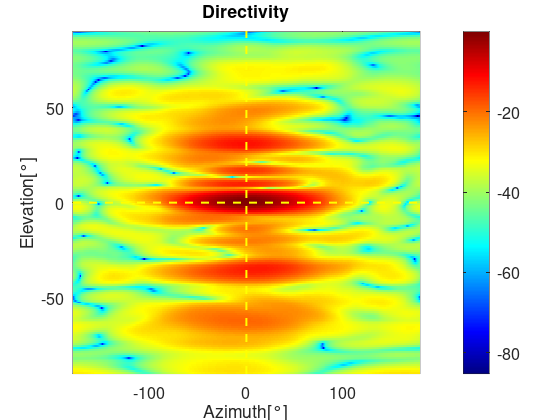

In [4]:
#Step 3: inspect the data
amp_dB_2D = reshape(amp_dB, theta_steps,phi_steps);
% imagesc(flipud(amp_dB_2D));colormap(jet)
pcolor(phi,theta-90,amp_dB_2D);colormap(jet);shading flat;colorbar
% daspect([1 2 1]);
xlabel('Azimuth[°]')
ylabel('Elevation[°]')
hold on
plot(xlim,[0 0],'y--')
plot([0 0],ylim,'y--')
title('Directivity')

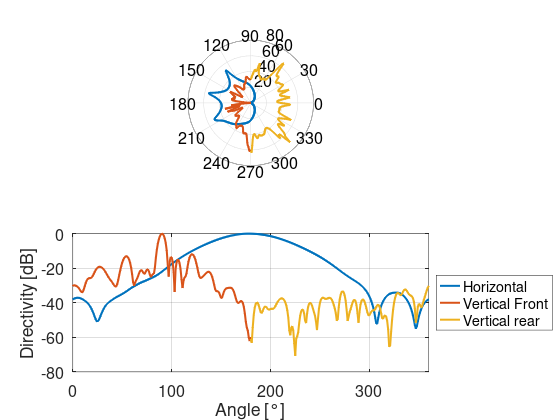

In [5]:
# Step 4: extract the V and H pattern cuts
h = amp_dB_2D(91,:); # Horizontal
vf = amp_dB_2D(:,180);         # Vertical Front
vr = amp_dB_2D(:,1);           # Vertical Rear


# Step 5: inspect the extracted cuts
figure
subplot(211)
polar(pi*(0:360)/180,h);grid on
hold on
polar(pi*(-90:90)/180,vf); hold on
polar(pi*(90:270)/180,flipud(vr))

subplot(212)
plot(0:360,(h));grid
xlim([0,360]); hold on
plot(0:180,vf);
plot(180:360,flipud(vr))
legend('Horizontal','Vertical Front','Vertical rear','location','eastoutside')
xlabel('Angle [°]')
ylabel('Directivity [dB]')

In [6]:
# Step 6. Verify consistency
disp('main direction of radiation:')
disp(' H plane')
[max_h, index_max_h] = max(h)
disp(' V plane')
[max_vf, index_max_vf] = max(vf)

disp('-----------------------------')
disp('rear H')
index_rear_h = 1
h(1)
h(361)
disp('-----------------------------')
disp('rear V')
index_rear_v = 91
vr(index_rear_v)

main direction of radiation:
 H plane
max_h = -0.015000
index_max_h = 179
 V plane
max_vf = -0.016000
index_max_vf = 91
-----------------------------
rear H
index_rear_h = 1
ans = -38.013
ans = -38.014
-----------------------------
rear V
index_rear_v = 91
ans = -38.013


In order to align the diagrams in polar plot, one will trim the lowest level at a conveninet value (i.e., - 40 dB). The flexibility of polar plot in GNU Octave is limited.

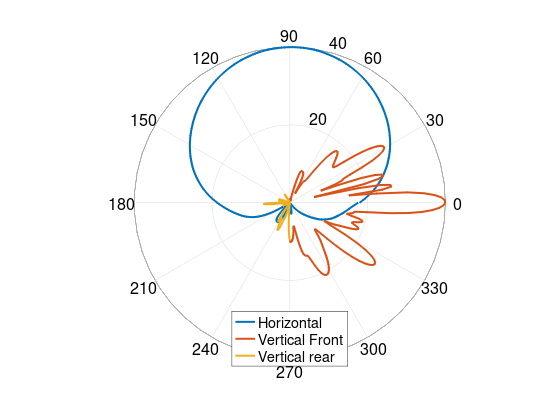

In [7]:
# Step 7. Represent properly the polar pattern
h_lim = max(h,-40);
vf_lim = max(vf,-40);
vr_lim = max(vr,-40);

polar(pi*(0:360)/180,circshift(h_lim+40,-90));
hold on
polar(pi*(-90:90)/180,vf_lim+40); 
polar(pi*(90:270)/180,flipud(vr_lim)+40)
legend('Horizontal','Vertical Front','Vertical rear','location','south')

Skeleton graph adds a spectacular view of the plane cuts vs 2D pattern:

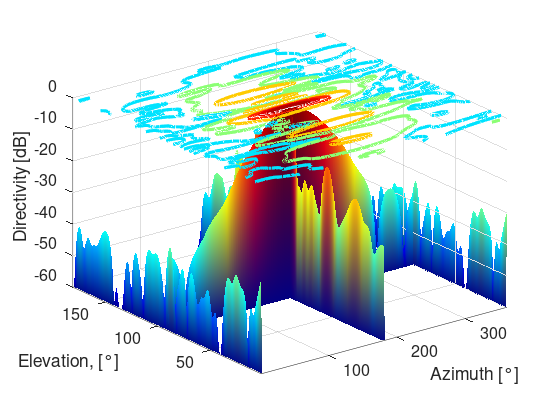

In [8]:
floor_dB = -61;
h_lim =  max(h ,floor_dB);
vf_lim = max(vf,floor_dB);
vr_lim = max(vr,floor_dB);

skeleton = zeros([181,361])+floor_dB;
skeleton(91,:)=h_lim;
skeleton(:,1)= vr_lim;
skeleton(:,181)= vf_lim;
skeleton(:,361)= vr_lim;
surf(skeleton);
shading interp;colormap(jet)
axis([1 361 1 181 -60 0]);
hold on
contour(amp_dB_2D, [-40 -30 -20 -10  -6 -3],'linewidth',3)
xlabel('Azimuth [°]');
ylabel('Elevation, [°]');
zlabel('Directivity [dB]')


In [9]:
# Step 8: Conversion into linear values:
H  = 10.^(h /20); % linear h, line vector
VF = 10.^(vf/20); % linear vf, column vector
VR = 10.^(vr/20); % linear vr, column vector

The simplest algorithm is the pattern multiplication (in linear units) or pattern summation (in log units):

$$ \mathbf C (\theta, \varphi) = \mathbf V_F^T(\theta) \mathbf  \cdot H(\varphi)$$

where 

$\mathbf C (\theta, \varphi)$ is the $0 dB$ normalized pattern matrix

$ \mathbf H(\varphi) $ is the line vector of horizontal pattern cut in linear units

$ \mathbf V_F(\varphi) $ is the line vector of vertical front pattern cut in linear units.



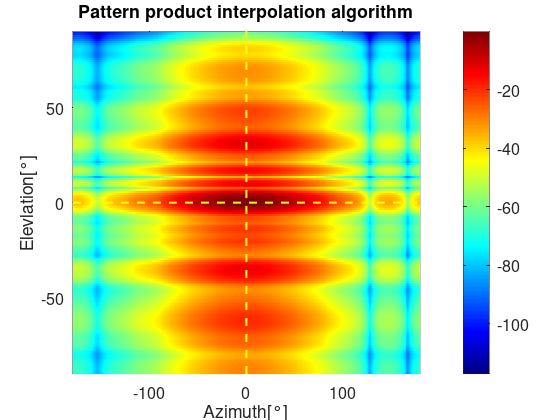

In [10]:
# Step 9.1. Pattern calculation with multiplication:
C = VF*H;

c = 20*log10(C);

cc = c;
pcolor(phi,theta-90,cc); shading flat; colormap(jet); colorbar
title('Pattern product interpolation algorithm')
xlabel('Azimuth[°]')
ylabel('Elevlation[°]')
hold on
plot(xlim,[0 0],'y--')
plot([0 0],ylim,'y--')

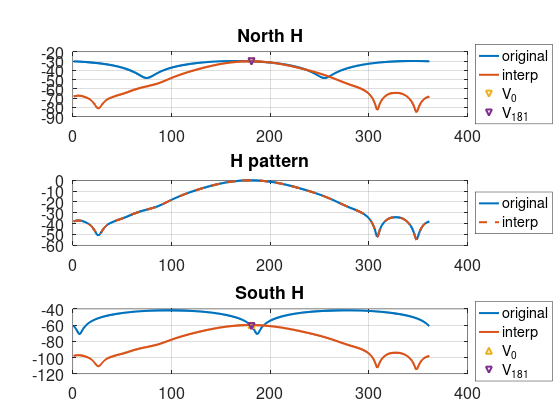

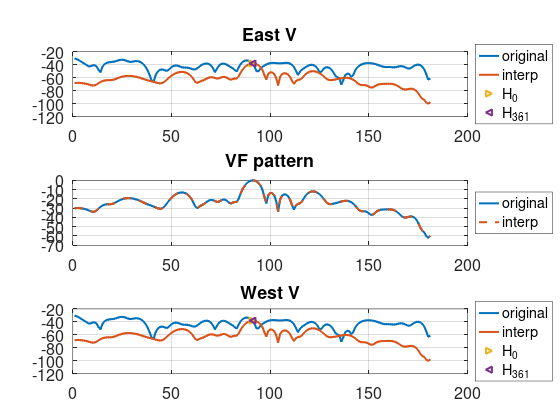

In [11]:
# Step 9.2 Verify consistency
figure;

subplot(311); plot(amp_dB_2D(1,:)); hold on;plot(cc(1,:));grid; plot(181,vf(1),'v'); plot(181,vr(1),'v'); 
title('North H');legend('original', 'interp','V_0','V_{181}','location','eastoutside')

subplot(312);plot(h); grid; hold on; plot(cc(91,:),'--'); title('H pattern')
legend('original', 'interp','location','eastoutside')

subplot(313); plot(amp_dB_2D(181,:)); hold on;plot(cc(181,:));grid; plot(181,vf(end),'^'); plot(181,vr(end),'v'); 
title('South H');legend('original', 'interp','V_0','V_{181}','location','eastoutside')


figure

subplot(311); plot(amp_dB_2D(:,1)); hold on; plot(cc(:,1)); plot(91,h(1),'>'); plot(91,h(end),'<');grid; title('East V')
legend('original', 'interp','H_0','H_{361}','location','eastoutside')

subplot(312);plot(vf); grid; hold on; plot(c(:,181),'--'); title('VF pattern')
legend('original', 'interp','location','eastoutside')

subplot(313); plot(amp_dB_2D(:,end)); hold on; plot(cc(:,end)); plot(91,h(1),'>'); plot(91,h(end),'<');grid; title('West V')
legend('original', 'interp','H_0','H_{361}','location','eastoutside')

It can be seen that, while on the front H and V cuts the interpolation is consistent, in back (east and weast) it is not.
North ans South are correct at poles, but the original pattern has different values at the poles, the first and last line should be a constant.

Our algorithm solves these issues.

The algorithm from the published paper:

$$C(\theta,\varphi) = \left( \frac{H(\varphi) \cdot \sin^2\theta}{VF(\frac{\pi}{2}) \cdot \cos^2\frac{\varphi}{2} + VR(\frac{\pi}{2}) \cdot \sin^2\frac{\varphi}{2}} + \cos^2\theta \right) \cdot \left( VF(\theta) \cdot \cos^2\frac{\varphi}{2} + VR(\theta) \cdot \sin^2\frac{\varphi}{2} \right)$$

An equivalent formulation:

$$C(\theta,\varphi) =  
        \frac{\ VF(\theta) \cdot \cos^2\frac{\varphi}{2} + VR(\theta) \cdot \sin^2\frac{\varphi}{2}}
        {VF(\frac{\pi}{2}) \cdot \cos^2\frac{\varphi}{2} + VR(\frac{\pi}{2}) \cdot \sin^2\frac{\varphi}{2}}
        \cdot H(\varphi) \cdot \sin^2\theta
+ \left( VF(\theta) \cdot \cos^2\frac{\varphi}{2} + VR(\theta) \cdot \sin^2\frac{\varphi}{2} \right)\cdot \cos^2\theta $$

The function implementing it is below, written in vectorised manner.

In [12]:
# Step 10. Implement the interpolation function

function C3D = aint3d(VF, VR, H)
  % AINT3D Implements the 3D interpolation method for the radiation pattern.
  % Source: T. Petrita & A. Ignea, ISETC 2012 (DOI: 10.1109/ISETC.2012.6408150)
  %
  % Arguments:
  % VF - Vector (181x1 or 1x181): Front vertical pattern (Theta: 0 to 180 deg)
  % VR - Vector (181x1 or 1x181): Rear vertical pattern (Theta: 180 to 0 deg)
  % H  - Vector (361x1 or 1x361): Horizontal pattern (Phi: -180 to 180 deg)
  %
  % Output:
  % C3D - Matrix (181x361): Linear values of the interpolated field

  % 1. Define angle grids (in radians)
  theta = linspace(0, pi, 181)'; % Zenith (Vertical)  -- column vector
  phi   = linspace(-pi, pi, 361); % Azimuth (Horizontal) -- row vector

  % Force inputs to column orientation (fixes dimension mismatch if rows were passed)
  VF = VF(:);  % 181x1
  VR = VR(:);  % 181x1
  H  = H(:);   % 361x1
   
  % Align VR to the same theta grid as VF (Theta: 0 to pi)
  % (VR input is ordered Theta 180→0 deg, so flip to match indexing)
  % VR = flipud(VR);
  
  % Precompute weighting factors (vectorized, 1×361)
  c2_phi = cos(phi/2).^2;
  s2_phi = sin(phi/2).^2;

  % Vertical interpolated field Vi(θ,φ) = VF(θ)·cos²(φ/2) + VR(θ)·sin²(φ/2)
  % Result: 181×361 matrix
  Vi = VF * c2_phi + VR * s2_phi;
  
  % Vi at equator (θ = π/2, index 91)
  Vi_eq = VF(91) * c2_phi + VR(91) * s2_phi; % 1×361
  
  
  % Avoid division by zero (numerical safety)
  Vi_eq = max(Vi_eq, eps);
  
  % Theta weighting factors (181×1)
  c2_theta = cos(theta).^2;
  s2_theta = sin(theta).^2;
  

  % H as row vector for broadcasting (1×361)
  H_row = H';

  % Multiplier = cos²θ + sin²θ · (H(φ) / Vi_eq(φ))
  % Result: 181×361 matrix
  multiplier = c2_theta * ones(1, 361) + s2_theta * (H_row ./ Vi_eq);
  
  
  % Final interpolated linear field (formula 12)
  C3D = Vi .* multiplier;
  
end

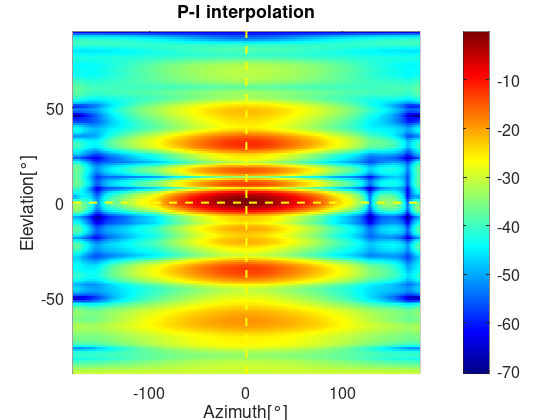

In [13]:
# Step 12. Interpolate!

  CC = aint3d(VF, VR, H);
  cc = 20*log10(CC);
  % imagesc(cc); colormap(jet)
  
  
  
  figure
    pcolor(phi,theta-90,cc); shading flat; colormap(jet); colorbar
    title('P-I interpolation')
    xlabel('Azimuth[°]')
    ylabel('Elevlation[°]')
    hold on
    plot(xlim,[0 0],'y--')
    plot([0 0],ylim,'y--')



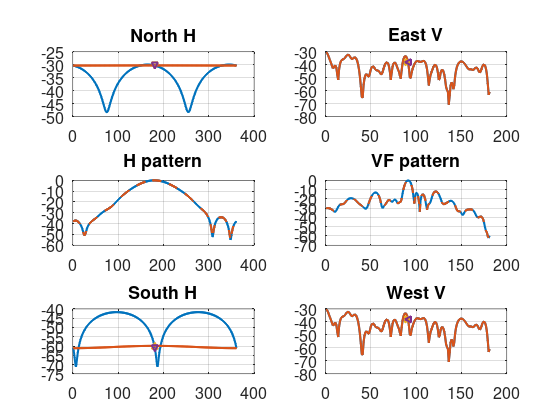

In [14]:
# Step 13. Check consistency
figure;

subplot(321); plot(amp_dB_2D(1,:)); hold on;plot(cc(1,:));grid; plot(181,vf(1),'v'); plot(181,vr(1),'v'); 
title('North H')
subplot(323);plot(h); grid; hold on; plot(cc(91,:),'--'); 
title('H pattern')
subplot(325); plot(amp_dB_2D(181,:)); hold on;plot(cc(181,:));grid; plot(181,vf(end),'^'); plot(181,vr(end),'v'); 
title('South H')
subplot(322); plot(amp_dB_2D(:,1)); hold on; plot(cc(:,1)); plot(91,h(1),'>'); plot(91,h(end),'<');grid; 
title('East V')
subplot(324);plot(vf); grid; hold on; plot(c(:,181),'--'); 
title('VF pattern')
subplot(326); plot(amp_dB_2D(:,end)); hold on; plot(cc(:,end)); plot(91,h(1),'>'); plot(91,h(end),'<');grid; 
title('West V')

Finally, a visual comparison between interpolations, scalled as filled contour in the same range.

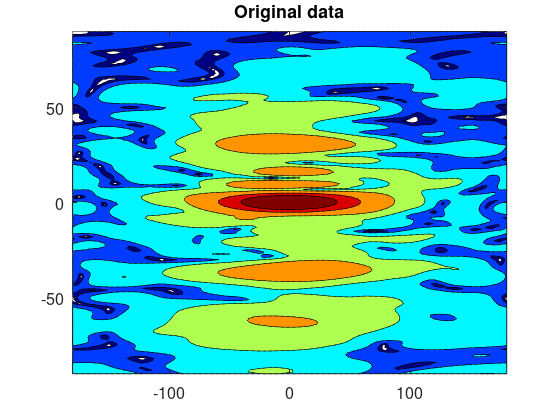

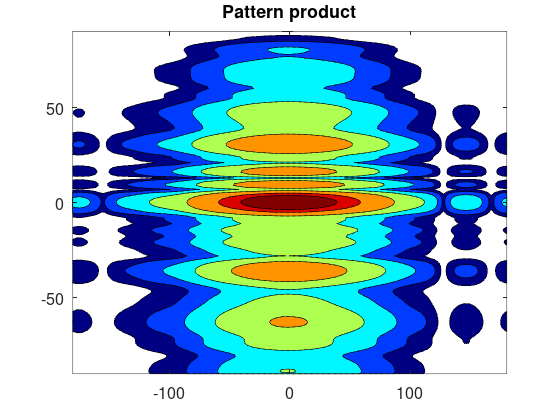

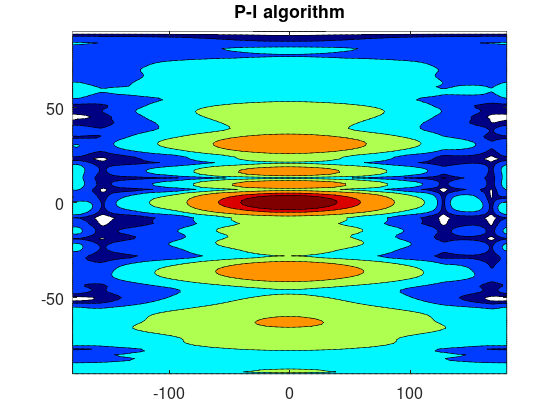

In [15]:
# Step 14 Compare and evaluate

figure;
contourf(phi,theta-90,amp_dB_2D,[-60 -50 -40 -30 -20 -10 -5]); colormap(jet)
title('Original data')
figure;
contourf(phi,theta-90,c,        [-60 -50 -40 -30 -20 -10 -5]); colormap(jet)
title('Pattern product')
figure;
contourf(phi,theta-90,cc,       [-60 -50 -40 -30 -20 -10 -5]); colormap(jet)
title('P-I algorithm')

---
### Copyright & License

Copyright (C) 2012-2026 T. Petrita & A. Ignea.

This program is free software: you can redistribute it and/or modify
it under the terms of the GNU General Public License as published by
the Free Software Foundation, either version 3 of the License, or
(at your option) any later version.

This program is distributed in the hope that it will be useful,
but WITHOUT ANY WARRANTY; without even the implied warranty of
MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the
[GNU General Public License](https://www.gnu.org/licenses/) for more details.

**Citation Requirement:**
If you use this algorithm or code in your research, please cite the original paper:
> T. Petrita and A. Ignea, "A new method for interpolation of 3D antenna pattern from 2D plane patterns," 2012 10th International Symposium on Electronics and Telecommunications (ISETC), Timisoara, Romania, 2012, pp. 393-396. DOI: 10.1109/ISETC.2012.6408150